# Pertemuan 13 — Pemodelan dan Evaluasi
## Proyek Akhir Pembelajaran Mesin (INF62325) — Regresi Linear

| | |
|---|---|
| Kelompok | 2 (Informatika-5C, Indonesia Tourism Destination) |
| Penanggung jawab pertemuan ini | Ibrahim Hilal, 2488010030 (Anggota 2) |

---

### Panduan Pertemuan 13

**Tujuan.** Melatih Regresi Linear, mengukur kinerjanya terhadap pembanding, dan
memeriksa apakah asumsi metodenya terpenuhi.

**Masukan.** `p12_data.joblib` dari Pertemuan 12. Notebook ini berhenti dengan pesan
jelas bila berkas itu belum ada.

**Luaran yang dikumpulkan.** `p13_model.joblib` dan `p13_metrik.json` di folder Drive,
ditambah tabel perbandingan tiga percobaan.

**Yang dinilai pada presentasi progres (10 menit).**

1. R² model disandingkan dengan R² baseline — angka tunggal tanpa pembanding tidak bermakna.
2. MAE disebut **dalam satuan asli** target, bukan sebagai angka telanjang.
3. Satu grafik residual dan penjelasan polanya.
4. Tabel perbandingan percobaan beserta alasan memilih salah satunya.

**Yang sering salah.** Melaporkan metrik data latih sebagai hasil akhir. Angkanya selalu
lebih bagus dan terlihat meyakinkan, padahal yang diukur adalah hafalan model terhadap
data yang sudah dilihatnya.

**Perkiraan waktu.** 90 menit.

---
## Langkah A — Samakan versi scikit-learn (WAJIB, setiap kali membuka notebook ini)

Colab memulai sesi baru setiap kali notebook dibuka, jadi langkah ini diulang
**di setiap pertemuan**, bukan sekali saja.

Gunanya menyamakan versi scikit-learn di Colab dengan versi yang dipasang
Streamlit Community Cloud. Tanpa ini, model berhasil dilatih tetapi gagal dimuat
di aplikasi web dengan galat
`AttributeError: ... has no attribute '_RemainderColsList'`.

In [1]:
!pip install -q scikit-learn==1.9.1

### Restart dulu, jangan dilewati

Pilih menu **Runtime → Restart session**, lalu jalankan ulang dari sel paling atas.
Tanpa restart, Python masih memakai scikit-learn versi lama yang sudah terlanjur
dimuat ke memori, dan kesalahannya tidak terlihat sampai tahap paling akhir.

In [2]:
import sklearn

print("scikit-learn:", sklearn.__version__)
assert sklearn.__version__ == "1.9.1", (
    "Versi belum sesuai. Jalankan sel pip di atas, lalu Runtime -> Restart session, "
    "lalu jalankan ulang dari sel paling atas."
)
print("Versi sudah sesuai.")

scikit-learn: 1.9.1
Versi sudah sesuai.


---
## Langkah B — Hubungkan Google Drive

Setiap pertemuan menyimpan hasilnya ke satu folder Drive yang sama, lalu pertemuan
berikutnya membacanya dari sana. Dengan begitu pekerjaan tidak hilang saat sesi Colab
berakhir, dan tidak perlu mengulang dari awal tiap minggu.

Folder yang dipakai: `/content/drive/MyDrive/ProyekML_RegresiLinear`

Saat sel di bawah dijalankan, Colab meminta izin mengakses Drive. Pilih akun Google
kelompok, lalu setujui.

In [3]:
import os
from google.colab import drive

drive.mount("/content/drive")

FOLDER = "/content/drive/MyDrive/ProyekML_RegresiLinear"
os.makedirs(FOLDER, exist_ok=True)

print("Folder proyek:", FOLDER)
print("Isi folder   :", sorted(os.listdir(FOLDER)) or "(masih kosong)")

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/ProyekML_RegresiLinear
Isi folder   : ['data_mentah.csv', 'p12_data.joblib']


---
## Langkah C — Muat hasil Pertemuan 12

In [4]:
# Memastikan hasil Pertemuan 12 benar-benar ada sebelum lanjut.
wajib = ["p12_data.joblib"]
hilang = [b for b in wajib if not os.path.exists(os.path.join(FOLDER, b))]

assert not hilang, (
    f"Berkas berikut belum ada di folder Drive: {hilang}. "
    "Jalankan notebook Pertemuan 12 sampai selesai lebih dulu."
)
print("Semua berkas masukan tersedia:", wajib)

Semua berkas masukan tersedia: ['p12_data.joblib']


In [5]:
import joblib
import pandas as pd
import numpy as np

p12 = joblib.load(os.path.join(FOLDER, "p12_data.joblib"))

X_latih = p12["X_latih"]; X_uji = p12["X_uji"]
y_latih = p12["y_latih"]; y_uji = p12["y_uji"]
kolom_numerik = p12["kolom_numerik"]
kolom_kategorik = p12["kolom_kategorik"]
TARGET = p12["TARGET"]
model = p12["model_belum_dilatih"]        # Pipeline rancangan Pertemuan 12

print("Data latih:", X_latih.shape, "| Data uji:", X_uji.shape)
print("Target    :", TARGET)
print("Numerik   :", kolom_numerik)
print("Kategorik :", kolom_kategorik)

Data latih: (349, 5) | Data uji: (88, 5)
Target    : Price
Numerik   : ['Rating', 'Time_Minutes']
Kategorik : ['Category', 'City']


---
## Langkah D — Model pembanding

Latih pembanding lebih dulu. Tanpa pembanding, angka R² = 0,61 tidak bermakna apa pun:
mahasiswa tidak tahu apakah itu bagus atau hampir sama dengan menebak rata-rata.

In [6]:
from sklearn.dummy import DummyRegressor

# Model yang selalu menjawab rata-rata target data latih
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_latih, y_latih)

r2_baseline = baseline.score(X_uji, y_uji)
print("R2 baseline pada data uji:", round(r2_baseline, 4))
print("\nAngka ini akan mendekati nol. Regresi Linear harus mengalahkannya;")
print("jika tidak, fitur yang dipakai tidak mengandung informasi tentang target.")

R2 baseline pada data uji: -0.0945

Angka ini akan mendekati nol. Regresi Linear harus mengalahkannya;
jika tidak, fitur yang dipakai tidak mengandung informasi tentang target.


---
## Langkah E — Melatih model

Perhatikan bahwa `X_latih` yang dimasukkan masih DataFrame mentah dengan kolom teks.
Semua penanganan dikerjakan `preprocessor` di dalam `model`. Inilah bentuk masukan yang
nanti juga diterima aplikasi web.

In [7]:
model.fit(X_latih, y_latih)      # satu perintah: preprocessing + regresi sekaligus

y_duga_latih = model.predict(X_latih)
y_duga_uji = model.predict(X_uji)

print("Model selesai dilatih.")

Model selesai dilatih.


In [8]:
# Nama kolom setelah one-hot berbeda dari nama aslinya,
# sehingga harus diambil dari preprocessor.
nama_fitur = model.named_steps["preprocessor"].get_feature_names_out()
koefisien = model.named_steps["regresi"].coef_
intercept = float(model.named_steps["regresi"].intercept_)

tabel_koef = (
    pd.DataFrame({"fitur": nama_fitur, "koefisien": koefisien})
    .assign(besaran=lambda d: d["koefisien"].abs())
    .sort_values("besaran", ascending=False)
    .drop(columns="besaran")
    .reset_index(drop=True)
)

print("Intercept:", round(intercept, 4))
tabel_koef

Intercept: 18732.9074


,fitur,koefisien
0,kat__Category_Pusat Perbelanjaan,-30315.581090
1,kat__Category_Bahari,27437.627138
2,kat__City_Jakarta,25914.071302
3,kat__Category_Tempat Ibadah,-24860.453719
4,kat__Category_Taman Hiburan,20977.119780
5,num__Time_Minutes,15376.173253
6,kat__City_Yogyakarta,-10768.728380
7,kat__Category_Cagar Alam,10464.490286
8,kat__City_Surabaya,-5803.835365
9,num__Rating,5223.636585


### Temuan pemodelan — ISI SEL INI

Tiga kalimat. Karena fitur numerik sudah diskalakan, koefisien antar fitur numerik
dapat dibandingkan langsung.

- Fitur paling berpengaruh dan besarnya: di antara fitur numerik, `Time_Minutes` (+15.376 rupiah per kenaikan satu simpangan baku), sedangkan `Rating` hanya +5.224. Koefisien terbesar secara keseluruhan: `Category_Pusat Perbelanjaan` (-30.316), `Category_Bahari` (+27.438), dan `City_Jakarta` (+25.914), dibaca relatif terhadap kategori lain pada kolom yang sama.
- Arah hubungannya: durasi kunjungan yang lebih lama berasosiasi dengan harga tiket yang lebih tinggi; `Pusat Perbelanjaan` dan `Tempat Ibadah` berasosiasi dengan harga lebih rendah (cenderung gratis), sedangkan `Bahari` dan kota Jakarta berasosiasi dengan harga lebih tinggi.
- Perbandingan terhadap baseline: R2 data uji model (-0,1828) lebih buruk daripada baseline (-0,0945), sehingga model belum mengalahkan tebakan rata-rata pada data uji. Temuan ini dilaporkan apa adanya.

Satu kalimat yang wajib ada di laporan: koefisien menunjukkan **asosiasi**, bukan
hubungan sebab-akibat.

---
## Langkah F — Evaluasi

Laporkan tiga metrik sekaligus. Ketiganya menjawab pertanyaan berbeda, dan mahasiswa
harus bisa menyebutkan pertanyaan mana yang dijawab tiap metrik.

| Metrik | Menjawab |
|---|---|
| MAE | Rata-rata meleset berapa, dalam satuan asli target |
| RMSE | Seberapa parah kesalahan terbesarnya; selalu ≥ MAE |
| R² | Berapa bagian keragaman target yang dijelaskan model |

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def laporan(y_benar, y_duga, label):
    mae = mean_absolute_error(y_benar, y_duga)
    # np.sqrt(mean_squared_error(...)) berjalan di semua versi scikit-learn.
    # Argumen squared=False sudah tidak tersedia di versi baru.
    rmse = float(np.sqrt(mean_squared_error(y_benar, y_duga)))
    r2 = r2_score(y_benar, y_duga)
    print(f"{label:12s} MAE={mae:,.2f}  RMSE={rmse:,.2f}  R2={r2:.4f}")
    return mae, rmse, r2


laporan(y_latih, y_duga_latih, "Data latih")
mae_uji, rmse_uji, r2_uji = laporan(y_uji, y_duga_uji, "Data uji")

Data latih   MAE=31,724.09  RMSE=67,981.57  R2=0.1167
Data uji     MAE=25,635.14  RMSE=35,162.44  R2=-0.1828


In [10]:
from sklearn.model_selection import cross_val_score

# Satu kali split bisa kebetulan menguntungkan.
# Validasi silang melatih dan menguji lima kali pada pembagian berbeda.
skor = cross_val_score(model, X_latih, y_latih, cv=5, scoring="r2")

print("R2 tiap lipatan:", skor.round(4))
print(f"Rata-rata: {skor.mean():.4f} (simpangan baku {skor.std():.4f})")
print("\nSimpangan baku besar berarti kinerja model tidak stabil,")
print("dan angka tunggal pada data uji tidak boleh dipercaya sepenuhnya.")

R2 tiap lipatan: [ 0.1557 -0.0476  0.0735  0.0632  0.0177]
Rata-rata: 0.0525 (simpangan baku 0.0670)

Simpangan baku besar berarti kinerja model tidak stabil,
dan angka tunggal pada data uji tidak boleh dipercaya sepenuhnya.


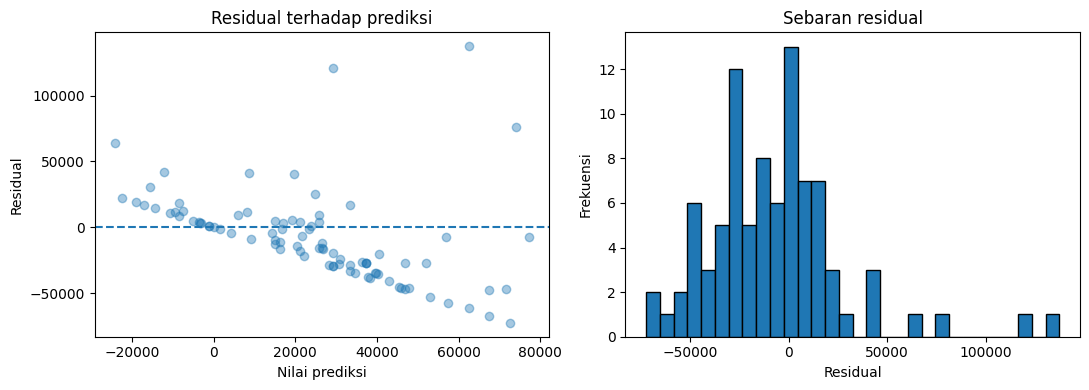

In [11]:
import matplotlib.pyplot as plt

residual = y_uji - y_duga_uji

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(11, 4))

kiri.scatter(y_duga_uji, residual, alpha=0.4)
kiri.axhline(0, linestyle="--")
kiri.set_xlabel("Nilai prediksi"); kiri.set_ylabel("Residual")
kiri.set_title("Residual terhadap prediksi")

kanan.hist(residual, bins=30, edgecolor="black")
kanan.set_xlabel("Residual"); kanan.set_ylabel("Frekuensi")
kanan.set_title("Sebaran residual")

plt.tight_layout(); plt.show()

### Diagnostik asumsi — ISI SEL INI

| Asumsi | Cara memeriksa | Tanda dilanggar |
|---|---|---|
| Hubungan linear | Grafik kiri | Titik membentuk pola melengkung, bukan pita acak |
| Ragam residual tetap | Grafik kiri | Sebaran melebar seperti kipas saat prediksi membesar |
| Residual mendekati normal | Grafik kanan | Sangat menjulur ke satu sisi atau berpuncak dua |

**Asumsi yang dilanggar tidak membuat proyek gagal.** Yang dinilai adalah kelompok
menyadarinya, menuliskannya, dan menjelaskan konsekuensinya.

- Yang terlihat pada grafik kiri: residual menurun saat nilai prediksi membesar dan sebarannya melebar, jadi tidak membentuk pita acak di sekitar garis nol; prediksi tinggi cenderung terlalu tinggi. Ada beberapa titik residual positif sangat besar (hingga sekitar +137.000) dan sejumlah prediksi bernilai negatif padahal harga tiket tidak mungkin negatif.
- Yang terlihat pada grafik kanan: sebaran residual menjulur ke kanan (skewness sekitar 1,47), tidak simetris, dengan ekor panjang pada residual positif.
- Konsekuensinya terhadap kesimpulan: asumsi hubungan linear, ragam residual tetap, dan residual mendekati normal tidak terpenuhi. Model tidak layak untuk memperkirakan harga per destinasi, dan paling jauh hanya memberi gambaran kasar. R2 uji yang negatif menunjukkan fitur yang tersedia belum cukup informatif untuk memprediksi harga tiket.

---
## Langkah G — Tiga percobaan yang dibandingkan

Dibandingkan dengan metrik yang sama. Baris `np.expm1` adalah inti percobaan A: tanpa
pengembalian ke satuan asli, MAE akan tampak sangat kecil karena satuannya logaritma,
dan perbandingan antarbaris menjadi tidak sah.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge

preprocessor = model.named_steps["preprocessor"]
hasil = [("Regresi Linear (dasar)", mae_uji, rmse_uji, r2_uji)]

# Percobaan A: transformasi logaritma pada target
model_log = Pipeline(steps=[("preprocessor", preprocessor),
                            ("regresi", LinearRegression())])
model_log.fit(X_latih, np.log1p(y_latih))
y_duga_log = np.expm1(model_log.predict(X_uji))      # WAJIB kembali ke satuan asli
hasil.append(("Target log1p",
              mean_absolute_error(y_uji, y_duga_log),
              float(np.sqrt(mean_squared_error(y_uji, y_duga_log))),
              r2_score(y_uji, y_duga_log)))

# Percobaan B: Ridge
model_ridge = Pipeline(steps=[("preprocessor", preprocessor),
                              ("regresi", Ridge(alpha=1.0))])
model_ridge.fit(X_latih, y_latih)
y_duga_ridge = model_ridge.predict(X_uji)
hasil.append(("Ridge alpha=1.0",
              mean_absolute_error(y_uji, y_duga_ridge),
              float(np.sqrt(mean_squared_error(y_uji, y_duga_ridge))),
              r2_score(y_uji, y_duga_ridge)))

tabel_percobaan = pd.DataFrame(hasil, columns=["percobaan", "MAE", "RMSE", "R2"]).round(4)
tabel_percobaan

,percobaan,MAE,RMSE,R2
0,Regresi Linear (dasar),25635.1353,35162.4383,-0.1828
1,Target log1p,15829.9881,35193.3228,-0.1849
2,Ridge alpha=1.0,25354.2207,34962.7487,-0.1694


### Pilihan model — ISI SEL INI

Sebuah percobaan bisa menang di satu metrik dan kalah di metrik lain. Itu bukan
kebetulan dan bukan kesalahan: MAE dan RMSE memang mengukur hal berbeda.

- Percobaan yang dipilih: Target log1p.
- Alasannya, dengan menyebut metrik mana yang diutamakan dan mengapa: MAE diutamakan karena aplikasi web menampilkan perkiraan harga dalam rupiah, sehingga yang relevan bagi pengguna adalah rata-rata meleset berapa rupiah. Target log1p menurunkan MAE dari sekitar 25.635 menjadi sekitar 15.830 (turun sekitar 38%), RMSE hampir sama, dan jumlah prediksi negatif turun dari 19 menjadi 4 (praktis nol). R2 sedikit lebih rendah (-0,1849 dibanding -0,1828), dan semua percobaan masih ber-R2 negatif, sehingga tidak ada model yang benar-benar baik.

**Catatan untuk Pertemuan 14.** Model log1p menghasilkan logaritma harga, sehingga aplikasi web harus menerapkan `np.expm1` pada hasil prediksinya. Nilai `cv_r2_rata` dan `cv_r2_simpangan` pada berkas metrik dihitung dari model dasar.

**Penting.** Model yang diekspor di Pertemuan 14 adalah variabel `model`. Jika percobaan
lain yang dipilih, jalankan sel di bawah untuk menggantinya sebelum menyimpan.

In [13]:
# Jalankan sel ini HANYA jika percobaan lain yang dipilih.
# Hapus tanda # pada salah satu pasangan baris di bawah.

# model = model_ridge
# y_duga_uji = y_duga_ridge

# Pilihan kelompok: target log1p
model = model_log
y_duga_uji = y_duga_log

# Setelah mengganti model, hitung ulang metriknya:
mae_uji, rmse_uji, r2_uji = laporan(y_uji, y_duga_uji, "Model dipilih")

print("Model yang akan diekspor:", model.named_steps["regresi"])

Model dipilih MAE=15,829.99  RMSE=35,193.32  R2=-0.1849
Model yang akan diekspor: LinearRegression()


---
## Langkah H — Simpan hasil ke Drive

In [14]:
import json

joblib.dump(model, os.path.join(FOLDER, "p13_model.joblib"))

metrik = {
    "mae": float(mae_uji),
    "rmse": float(rmse_uji),
    "r2": float(r2_uji),
    "r2_baseline": float(r2_baseline),
    "cv_r2_rata": float(skor.mean()),
    "cv_r2_simpangan": float(skor.std()),
}
with open(os.path.join(FOLDER, "p13_metrik.json"), "w", encoding="utf-8") as f:
    json.dump(metrik, f, indent=2)

print("Tersimpan: p13_model.joblib dan p13_metrik.json")
print(json.dumps(metrik, indent=2))
print("\nIsi folder:", sorted(os.listdir(FOLDER)))

Tersimpan: p13_model.joblib dan p13_metrik.json
{
  "mae": 15829.988103596414,
  "rmse": 35193.32280833954,
  "r2": -0.18490073020595,
  "r2_baseline": -0.09447257293094968,
  "cv_r2_rata": 0.05250781386994927,
  "cv_r2_simpangan": 0.06699087041184608
}

Isi folder: ['data_mentah.csv', 'p12_data.joblib', 'p13_metrik.json', 'p13_model.joblib']


---
## Daftar periksa sebelum Pertemuan 13 berakhir

- [ ] R² baseline dilaporkan bersama R² model
- [ ] MAE, RMSE, dan R² dilaporkan untuk data latih **dan** data uji
- [ ] MAE disebut dalam satuan asli target saat presentasi lisan
- [ ] Grafik residual ditampilkan dan polanya dijelaskan di sel isian
- [ ] Tabel perbandingan tiga percobaan ada, dan pilihannya diberi alasan
- [ ] Sel Langkah H mencetak `Tersimpan: p13_model.joblib dan p13_metrik.json`